# Scaffold and Source
🎯 Objective: Analyze the prevalence of the different scaffolds in the marine polyketides and from where they have been isolated

## Imports

In [1]:
from amp import load, work_in_outputs
work_in_outputs("02_scaffold-source")
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['svg.fonttype'] = 'none'

import numpy as np

## Scaffold

In [2]:
# Import list of smiles
df_scaffold = load("compounds")
df_scaffold.head()

,ID,Name,Scaffold,Type,Subtype,SMILES,DOI_Structures,Semi_synthetic
0,AQ001,"6,6′-oxybis(1,3,8-trihydroxy-2-((S)-1-methoxyh...",anthraquinone,dimer,complex,OC1=CC(OC2=CC(O)=C(C(C(C(O)=C([C@@H](OC)CCCCC)...,10.1016/j.fitote.2018.11.015,0
1,AQ002,"6,6′-oxybis(1,3,8-trihydroxy-2-((S)-1-hydroxyh...",anthraquinone,dimer,complex,O=C1C2=C(C(C3=C1C=C(C=C3O)OC4=CC(O)=C5C(C(C6=C...,10.1016/j.fitote.2018.11.015,0
2,AQ003,1′-O-methylaverantin,anthraquinone,monomer,simple,OC1=CC(O)=C(C2=C1)C(C3=C(C2=O)C=C(O)C([C@@H](O...,10.1016/j.fitote.2018.11.015,0
3,AQ004,Averantin,anthraquinone,monomer,simple,OC1=CC(O)=C(C2=C1)C(C3=C(C2=O)C=C(O)C([C@@H](O...,10.1016/j.fitote.2018.11.015,0
4,AQ005,Averythrin,anthraquinone,monomer,simple,OC1=CC(O)=C(C2=C1)C(C3=C(C2=O)C=C(O)C(/C=C/CCC...,10.1016/j.fitote.2018.11.015,0


In [3]:
# fomatting Scaffolds series
df_scaffold['Scaffold'] = [x.strip() for x in df_scaffold['Scaffold']]
df_scaffold['Scaffold'].unique()

df_scaffold['Scaffold'] = df_scaffold['Scaffold'].astype('category')

In [4]:
# Report after the unique-compound table is created in the next cell.


In [5]:
# Copy dataframe and keep only unique compounds (ignore compounds attibuted to more than 1 scaffold)
df_scaffold_unique = df_scaffold.copy()
df_scaffold_unique.drop_duplicates(subset=['ID'],inplace=True)
print(f"Total number of unique compounds: {df_scaffold_unique.shape[0]}")


Total number of unique compounds: 246


In [6]:
# print the distribution by scaffold
print(f"distribution per scaffold: {df_scaffold['Scaffold'].value_counts()}; \n{df_scaffold['Scaffold'].value_counts(normalize=True)}")

distribution per scaffold: anthraquinone     119
diphenyl-ether     96
xanthone           25
benzophenone       13
Name: Scaffold, dtype: int64; 
anthraquinone     0.470356
diphenyl-ether    0.379447
xanthone          0.098814
benzophenone      0.051383
Name: Scaffold, dtype: float64


In [7]:
# Calculate distribution by scaffold dividing by semi-synthetic
type = {}
for x in df_scaffold['Scaffold'].unique():
    row, col = df_scaffold.loc[(df_scaffold['Scaffold'] == x) & (df_scaffold['Semi_synthetic'] == 1)].shape
    type[x+'_ss']= row

for x in df_scaffold['Scaffold'].unique():
    row, col = df_scaffold.loc[(df_scaffold['Scaffold'] == x) & (df_scaffold['Semi_synthetic'] == 0)].shape
    type[x+'_np']= row

df_scaffold2 = pd.DataFrame.from_dict(type,orient='index')
df_scaffold2.columns = ['Count']
df_scaffold2['Perc'] = df_scaffold2['Count'] / df_scaffold2['Count'].sum()
df_scaffold2

,Count,Perc
anthraquinone_ss,16,0.063241
benzophenone_ss,0,0.000000
diphenyl-ether_ss,12,0.047431
xanthone_ss,0,0.000000
anthraquinone_np,103,0.407115
benzophenone_np,13,0.051383
diphenyl-ether_np,84,0.332016
xanthone_np,25,0.098814


(-1.0999998713097625,
 1.0999982185608868,
 -1.0999963243077369,
 1.099999824967035)

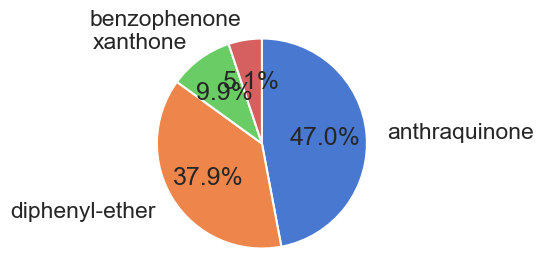

In [8]:
# Pie chart, where the slices will be ordered and plotted clockwise:
scaffolds = df_scaffold['Scaffold'].value_counts(normalize=True)
labels = scaffolds.index.values
sizes = scaffolds.values

#define Seaborn color palette to use
colors = sns.color_palette('muted')[0:4]

sns.set_context("talk")
sns.set_style("whitegrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }

fig1, ax1 = plt.subplots(figsize=(4, 3))


ax1.pie(sizes, labels=labels, autopct='%1.1f%%', shadow=False, startangle=90, counterclock=False, labeldistance=1.2, colors = colors)
ax1.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

#plt.savefig('pie_type.svg')

(-1.099997487928681,
 1.0999912265011078,
 -1.0999979883299171,
 1.0999999042061865)

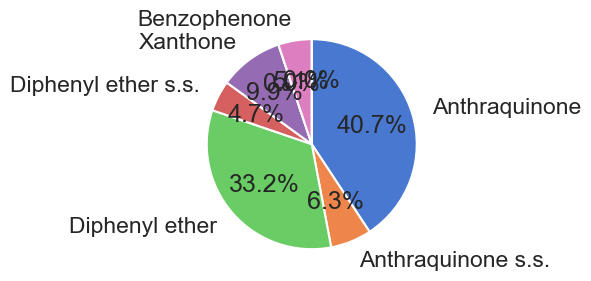

In [9]:
# Pie chart, where the slices will be ordered and plotted clockwise:
labels = ['anthraquinone_np', 'anthraquinone_ss','diphenyl-ether_np', 'diphenyl-ether_ss','xanthone_np', 'xanthone_ss','benzophenone_np','benzophenone_ss']
sizes = []
for name in labels:
        sizes.append(df_scaffold2.loc[name,'Perc'])

#define Seaborn color palette to use
colors = sns.color_palette('muted')[0:7]

sns.set_context("talk")
sns.set_style("whitegrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }

print_labels = ['Anthraquinone', 'Anthraquinone s.s.','Diphenyl ether', 'Diphenyl ether s.s.','Xanthone', '','Benzophenone','']

fig1, ax1 = plt.subplots(figsize=(4, 3))


ax1.pie(sizes, labels=print_labels, autopct='%1.1f%%', shadow=False, startangle=90, counterclock=False, labeldistance=1.2, colors = colors)
ax1.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

#plt.savefig('pie_distribution-scaffold.svg')

In [10]:
sizes

[0.40711462450592883,
 0.06324110671936758,
 0.33201581027667987,
 0.04743083003952569,
 0.09881422924901186,
 0.0,
 0.05138339920948617,
 0.0]

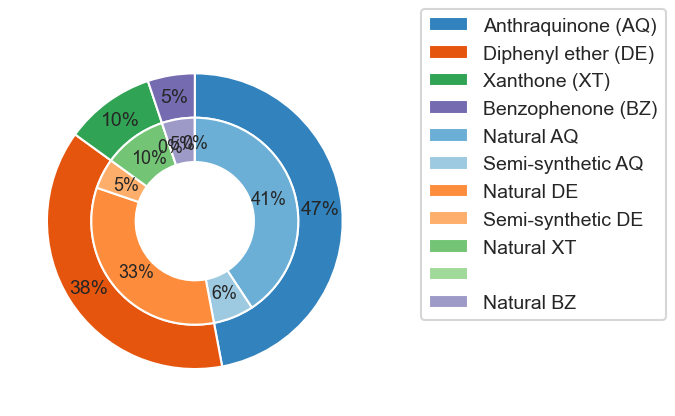

In [11]:
# Pie chart as donut
# colect labels and size from dataframe
labels = ['anthraquinone_np', 'anthraquinone_ss','diphenyl-ether_np', 'diphenyl-ether_ss','xanthone_np', 'xanthone_ss','benzophenone_np','benzophenone_ss']
sizes = []
for name in labels:
        sizes.append(df_scaffold2.loc[name,'Perc'])

# reorder array in pair of values for inner circle, the outer circle is obtained from summing the inner circle
vals = np.reshape(sizes,(4,2)) 

# call fig
fig, ax = plt.subplots()

# colors
cmap = plt.get_cmap("tab20c")
outer_colors = cmap(np.arange(4)*4)
inner_colors = cmap(np.array([1, 2, 5, 6, 9, 10, 13, 14]))

# size difference between the inner and otter circle
size = 0.3

print_labels = ['Anthraquinone (AQ)', 'Diphenyl ether (DE)', 'Xanthone (XT)', 'Benzophenone (BZ)', 'Natural AQ', 'Semi-synthetic AQ','Natural DE', 'Semi-synthetic DE', 'Natural XT', '','Natural BZ'] 

ax.pie(vals.sum(axis=1), radius=1, colors=outer_colors,
        autopct='%1.f%%', pctdistance=0.85,textprops={'fontsize': 14, 'color': '#262626'},
        startangle=90, counterclock=False,
       wedgeprops=dict(width=size, edgecolor='w'))

ax.pie(vals.flatten(), radius=1-size, colors=inner_colors,
        autopct='%1.f%%', pctdistance=0.75, textprops={'fontsize': 13, 'color': '#262626'},
       startangle=90, counterclock=False,
       wedgeprops=dict(width=size, edgecolor='w'))

ax.set(aspect="equal")

ax.legend(print_labels, loc="upper right", bbox_to_anchor=(1.8,1.1),fontsize= 14)

#plt.savefig('plots/pie_distribution-scaffold.svg')

## Source

In [12]:
# import data
df_source_all = load("sources")
df_source_all.head()

,ID,DOI_Source,Fungi_Genus,Fungi_Specie,Bacteria_Genus,Bacteria_Specie,Sponge_Genus,Sponge_Species,Strain,Semi_synthetic,Marine_Association,Associated_Specie,Sea,Region,Country
0,AQ001,10.1016/j.fitote.2018.11.015,Aspergillus,versicolor,NaN,NaN,NaN,NaN,NaN,NaN,clam,marine clam,East China Sea,NaN,China
1,AQ002,10.1016/j.fitote.2018.11.015,Aspergillus,versicolor,NaN,NaN,NaN,NaN,NaN,NaN,clam,marine clam,East China Sea,NaN,China
2,AQ003,10.1016/j.fitote.2018.11.015,Aspergillus,versicolor,NaN,NaN,NaN,NaN,NaN,NaN,clam,marine clam,East China Sea,NaN,China
3,AQ003,10.1007/s10600-020-03203-y,Aspergillus,versicolor,NaN,NaN,NaN,NaN,HBU-2017-7,NaN,NaN,NaN,Bohai Sea,NaN,China
4,AQ004,10.1016/j.fitote.2018.11.015,Aspergillus,versicolor,NaN,NaN,NaN,NaN,NaN,NaN,clam,marine clam,East China Sea,NaN,China


In [13]:
# fomatting 
# Remove white spaces
for x in df_source_all.columns:
    df_source_all[x] = df_source_all[x].map(lambda value: value.strip() if isinstance(value, str) else value)

df_source_all.head()

,ID,DOI_Source,Fungi_Genus,Fungi_Specie,Bacteria_Genus,Bacteria_Specie,Sponge_Genus,Sponge_Species,Strain,Semi_synthetic,Marine_Association,Associated_Specie,Sea,Region,Country
0,AQ001,10.1016/j.fitote.2018.11.015,Aspergillus,versicolor,NaN,NaN,NaN,NaN,NaN,NaN,clam,marine clam,East China Sea,NaN,China
1,AQ002,10.1016/j.fitote.2018.11.015,Aspergillus,versicolor,NaN,NaN,NaN,NaN,NaN,NaN,clam,marine clam,East China Sea,NaN,China
2,AQ003,10.1016/j.fitote.2018.11.015,Aspergillus,versicolor,NaN,NaN,NaN,NaN,NaN,NaN,clam,marine clam,East China Sea,NaN,China
3,AQ003,10.1007/s10600-020-03203-y,Aspergillus,versicolor,NaN,NaN,NaN,NaN,HBU-2017-7,NaN,NaN,NaN,Bohai Sea,NaN,China
4,AQ004,10.1016/j.fitote.2018.11.015,Aspergillus,versicolor,NaN,NaN,NaN,NaN,NaN,NaN,clam,marine clam,East China Sea,NaN,China


In [14]:
df_source = df_source_all[df_source_all['Semi_synthetic'].isna()].copy()
print(f'total number of sources: {df_source_all.shape[0]}, sources after removing semi synthetic compounds: {df_source.shape[0]}')

total number of sources: 252, sources after removing semi synthetic compounds: 224


In [15]:
# check compounds without any source
df_source[df_source['Fungi_Genus'].isna() & df_source['Bacteria_Genus'].isna() & df_source['Sponge_Species'].isna()]

,ID,DOI_Source,Fungi_Genus,Fungi_Specie,Bacteria_Genus,Bacteria_Specie,Sponge_Genus,Sponge_Species,Strain,Semi_synthetic,Marine_Association,Associated_Specie,Sea,Region,Country
144,DP018,10.1007/s00044-015-1386-9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,coral,Sinularia dura,NaN,NaN,Palau


### Distribution of compounds per microorganism with and without marine association

In [16]:
# list number of compounds per type
df_source.notna().sum()

ID                    224
DOI_Source            224
Fungi_Genus           149
Fungi_Specie          149
Bacteria_Genus         46
Bacteria_Specie        45
Sponge_Genus           76
Sponge_Species         76
Strain                150
Semi_synthetic          0
Marine_Association    154
Associated_Specie      79
Sea                    65
Region                177
Country               208
dtype: int64

In [17]:
# view for compounds isolated from a single source (several compounds have fungi and sponge fields) 
only_fungi = df_source[df_source['Fungi_Genus'].notna() & df_source['Bacteria_Genus'].isna()] # prefer bacteria when fungi and bacteria are available
only_bacteria = df_source[df_source['Bacteria_Genus'].notna()] # prefer bacteria when fungi and bacteria are available
only_sponge = df_source[df_source['Fungi_Genus'].isna() & df_source['Bacteria_Genus'].isna() & df_source['Sponge_Species'].notna()] # only when fungi or bacteria are not available

In [18]:
# Create a Dataframe with the number of compounds per microorganism with and without marine association

df_source_dist = pd.DataFrame(columns=['Marine_associated','Not_associated'],index=['Fungi','Bacteria','Sponge'])

df_source_dist.loc['Fungi','Marine_associated'] = only_fungi[only_fungi['Marine_Association'].notna()].shape[0]
df_source_dist.loc['Fungi','Not_associated'] = only_fungi[only_fungi['Marine_Association'].isna()].shape[0]
df_source_dist.loc['Bacteria','Marine_associated'] = only_bacteria[only_bacteria['Marine_Association'].notna()].shape[0]
df_source_dist.loc['Bacteria','Not_associated']  = only_bacteria[only_bacteria['Marine_Association'].isna()].shape[0]
df_source_dist.loc['Sponge','Marine_associated'] = only_sponge[only_sponge['Marine_Association'].notna()].shape[0]
df_source_dist.loc['Sponge','Not_associated']  = only_sponge[only_sponge['Marine_Association'].isna()].shape[0]

df_source_dist

,Marine_associated,Not_associated
Fungi,106,37
Bacteria,40,6
Sponge,7,27


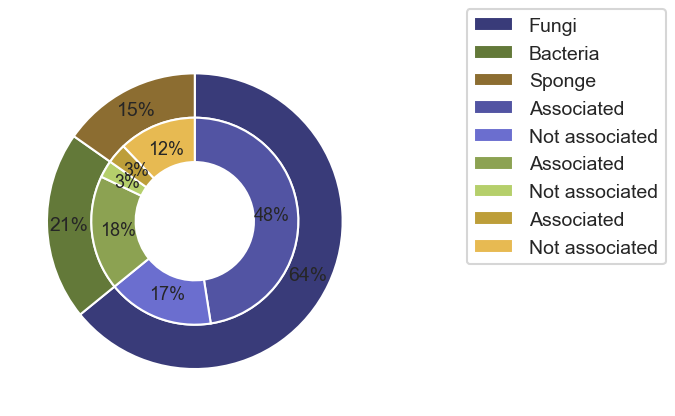

In [19]:
# Pie chart as donut
# colect labels and size from dataframe

df_source_dist.values
# reorder array in pair of values for inner circle, the outer circle is obtained from summing the inner circle
vals = df_source_dist.values

# call fig
fig, ax = plt.subplots()

# colors
cmap = plt.get_cmap("tab20b")
outer_colors = cmap(np.arange(3)*4)
inner_colors = cmap(np.array([1, 2, 5, 6, 9, 10]))

# size difference between the inner and otter circle
size = 0.3

print_labels = ['Fungi', 'Bacteria', 'Sponge', 'Associated', 'Not associated', 'Associated', 'Not associated','Associated', 'Not associated'] 

ax.pie(vals.sum(axis=1), radius=1, colors=outer_colors,
        autopct='%1.f%%', pctdistance=0.85,textprops={'fontsize': 14, 'color': '#262626'},
        startangle=90, counterclock=False,
       wedgeprops=dict(width=size, edgecolor='w'))

ax.pie(vals.flatten(), radius=1-size, colors=inner_colors,
        autopct='%1.f%%', pctdistance=0.75, textprops={'fontsize': 13, 'color': '#262626'},
       startangle=90, counterclock=False,
       wedgeprops=dict(width=size, edgecolor='w'))

ax.set(aspect="equal")

ax.legend(print_labels, loc="upper right", bbox_to_anchor=(1.8,1.1),fontsize= 14)

plt.savefig('plots/pie_distribution-sources.svg')

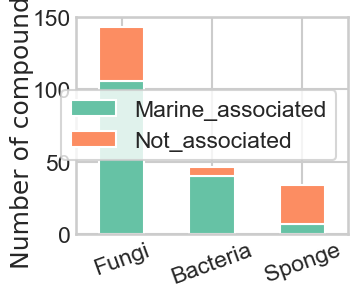

In [20]:
# plot 
sns.set_context("talk")
sns.set_style("whitegrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }
colors = sns.color_palette('Set2')[0:3]


f, ax = plt.subplots(figsize=(3.5, 3))
df_source_dist.plot(kind='bar', stacked=True,ax=ax, color=colors)

ax.set_box_aspect(0.8)
ax.tick_params(axis='both', which='major', pad=-5)

ax.set_ylabel("Number of compounds", fontdict=font,labelpad=-1)
plt.xticks(rotation=20)
plt.legend()

#plt.savefig('mw.svg')

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


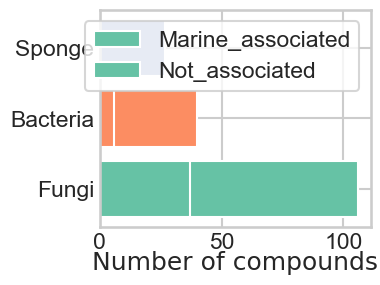

In [21]:
sns.set_context("talk")
sns.set_style("whitegrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }
colors = sns.color_palette('Set2')[0:3]


f, ax = plt.subplots(figsize=(3.5, 3))
b1 = plt.barh(df_source_dist.index, df_source_dist['Marine_associated'], color=colors)
b2 = plt.barh(df_source_dist.index, df_source_dist['Not_associated'], color=colors)

ax.set_box_aspect(0.8)
ax.tick_params(axis='both', which='major', pad=-5)

ax.set_xlabel("Number of compounds", fontdict=font,labelpad=-1)
plt.legend()

plt.legend([b1, b2], ["Marine_associated", "Not_associated"], loc="upper right")

#plt.savefig('mw.svg')

### Genus analysis

In [22]:
df_source['Fungi'] = df_source['Fungi_Genus'] + " " + df_source['Fungi_Specie']
df_source['Bacteria'] = df_source['Bacteria_Genus'] + " " + df_source['Bacteria_Specie']
df_source['Sponge'] = df_source['Sponge_Genus'] + " " + df_source['Sponge_Species']

In [23]:
all_species = pd.concat([df_source['Fungi_Genus'].value_counts(),df_source['Bacteria_Genus'].value_counts(),df_source['Sponge_Species'].value_counts()])
all_species.sort_values(ascending=False,inplace=True)

In [24]:
df_source['Fungi_Genus'].value_counts()

Aspergillus         75
Penicillium         16
Trichoderma         11
Sporendonema         7
Engyodontium         7
Nigrospora           5
Neosartorya          4
Talaromyces          4
Pseudogymnoascus     4
Eurotium             3
Pseudopithomyces     3
Curvularia           2
Chaetomium           2
Fusarium             1
Monodictys           1
Pestalotiopsis       1
Pestalotia           1
Sporidesmium         1
Dendrospora          1
Name: Fungi_Genus, dtype: int64

In [25]:
print(f"{df_source['Fungi_Genus'].value_counts()[0:2]} + \n + {df_source['Bacteria_Genus'].value_counts()[0:2]} + \n + {df_source['Sponge_Genus'].value_counts()[0:2]}")

Aspergillus    75
Penicillium    16
Name: Fungi_Genus, dtype: int64 + 
 + Streptomyces    27
Bacillus         5
Name: Bacteria_Genus, dtype: int64 + 
 + Lamellodysidea    12
Arenosclera        9
Name: Sponge_Genus, dtype: int64


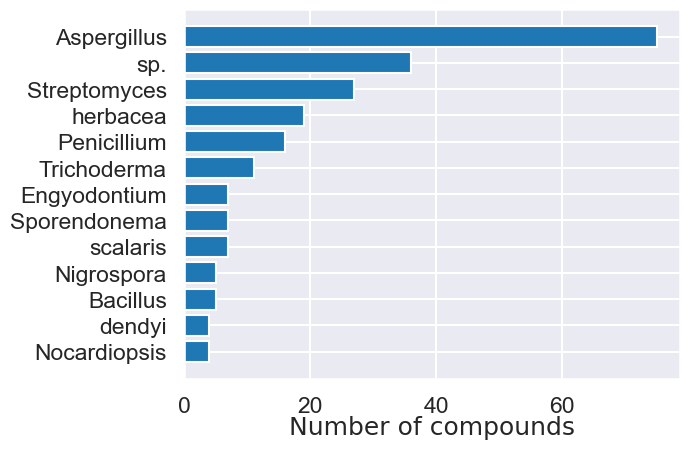

In [26]:
sns.set_context("talk")
sns.set_style("darkgrid")
font = {'family': 'DejaVu Sans',
        'color':  '#262626',
        'weight': 'normal',
        }


fig, ax = plt.subplots()
ax.barh(all_species.index[0:13], all_species.values[0:13])
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel("Number of compounds", fontdict=font,labelpad=-1)

plt.savefig('plots/bar_sources-frequent-species.svg')

### Country

In [27]:
df_source['Country'].fillna(value='N.A.',inplace=True)
df_source['Country'].value_counts()

China                             103
Indonesia                          24
N.A.                               16
Thailand                           12
Vietnam                             9
Antarctica                          8
Turkey                              8
Croatia                             7
Egypt                               6
Germany                             4
Puerto Rico                         4
Papua New Guinea                    4
USA                                 4
Korea                               3
Mexico                              3
West Pacific Ocean                  3
Bahamas                             1
Palau                               1
Japan                               1
Federated States of Micronesia      1
Canada                              1
India                               1
Name: Country, dtype: int64

In [28]:
df_source['Sea'].value_counts()

South China Sea       18
East China Sea         7
Bohai Sea              7
Yellow Sea             4
Wadden Sea             4
Beibu gulf             4
Honaunau reef          4
Laguna de Terminos     3
West Pacific Ocean     3
Red Sea                3
Aegean Sea             3
Egyptian Red Sea       2
Sea of Japan           1
Mediterranean Sea      1
Pacific Ocean          1
Name: Sea, dtype: int64